# 3.2. Generate montage to illustrate the PedCP90VS prediction dataset

PedCP90VS pairs label-free virtual-staining predictions with measured Cell Painting fluorescence. 
This notebook samples saved examples from selected biological conditions and places predictions from UNeXt, UNet, and wGAN alongside their fluorescence reference and bright-field input. 

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from utils.pair_dataset import PairedLanceImageDataset
from utils.validate_config import (
    load_yaml_config,
    require_config_directory,
)

In [2]:
# Helpers are defined before data loading; metadata is passed explicitly.
def _sql_string(value):
    """Quote a metadata value for a Lance SQL filter."""
    return "'" + str(value).replace("'", "''") + "'"


def condition_row_filter(condition, barcode_platemap_df):
    """Select plate/well pairs matching the requested biological condition."""
    matching_wells = barcode_platemap_df.loc[
        (barcode_platemap_df["cell_line"] == condition.cell_line)
        & (barcode_platemap_df["platemap_file"] == condition.platemap_file)
        & (barcode_platemap_df["seeding_density"] == condition.seeding_density),
        ["Metadata_Plate", "Metadata_Well"],
    ].drop_duplicates()

    if condition.well is not None:
        matching_wells = matching_wells[matching_wells["Metadata_Well"] == condition.well]
    if matching_wells.empty:
        raise ValueError(f"No plate/well mappings found for condition {condition!r}.")

    pair_clauses = [
        "("
        f"Metadata_Plate = {_sql_string(plate)} AND "
        f"Metadata_Well = {_sql_string(well)}"
        ")"
        for plate, well in matching_wells.itertuples(index=False, name=None)
    ]
    return "(" + " OR ".join(pair_clauses) + ")"


def sample_one_pair(dataset, rng):
    """Reservoir-sample one pair uniformly without retaining every image stack."""
    sampled_pair = None
    matching_rows = 0
    for matching_rows, pair in enumerate(dataset, start=1):
        if rng.integers(matching_rows) == 0:
            sampled_pair = pair
    if sampled_pair is None:
        raise ValueError("The condition matched no paired image records.")
    return sampled_pair, matching_rows


def add_scale_bar(
    ax,
    pixel_res: float,
    scale_bar_length: float | None = None,
    scalebar_loc: tuple[float, float] = (0.1, 0.9),
) -> None:
    """Draw a white bar; length is in pixels and pixel_res is µm per pixel."""
    if scale_bar_length is None:
        scale_bar_length = 50
    scale_bar_text = f"{scale_bar_length * pixel_res:.0f} µm"
    bar_height = 5
    bar_x = scalebar_loc[0] * ax.get_xlim()[1]
    bar_y = scalebar_loc[1] * ax.get_ylim()[0]
    rect = plt.Rectangle((bar_x, bar_y), scale_bar_length, bar_height, color="white")
    ax.add_patch(rect)
    ax.text(
        bar_x - 15, bar_y - 5, scale_bar_text,
        color="white", fontsize=8, ha="left", va="bottom",
    )

## Locate saved inputs and biological metadata

Read paths from the shared configuration, check required artifacts, and join barcode and platemap tables. No model is loaded or run in this notebook. The prediction catalog records the stack order used to label architecture and training-density panels.

In [3]:
# Support execution from either this notebook's directory or the repository root.
notebook_dir = Path.cwd()
if not (notebook_dir / "3.2.model_inference_montage.ipynb").is_file():
    notebook_dir = notebook_dir / "3.model_eval"
degradation_path = notebook_dir.parent / "1.image_degradation_simulation"
if not degradation_path.exists():
    raise FileNotFoundError(f"Degradation simulation directory not found: {degradation_path}")

config = load_yaml_config(degradation_path / "degradation_config.yaml")
analysis_dir = require_config_directory(config, "analysis_out_dir")
metadata_download_path = degradation_path / "metadata"
platemap_dir = metadata_download_path / "platemaps"
platemap_files = sorted(platemap_dir.glob("*_platemap.csv"))
if not platemap_files:
    raise FileNotFoundError(f"No platemap CSV files found in {platemap_dir}.")
barcode_file = metadata_download_path / "Barcode_platemap_pilot_data.csv"
if not barcode_file.exists():
    raise FileNotFoundError(f"Barcode platemap CSV file not found: {barcode_file}")

input_out_dir = analysis_dir / "patches" / "model_inference_inputs" / "OrigBrightfield"
target_out_dir = analysis_dir / "patches" / "model_inference_targets"
for required_path in (input_out_dir / "data.lance", target_out_dir):
    if not required_path.exists():
        raise FileNotFoundError(f"Required input missing: {required_path}. Run the 3.0 notebooks first.")

pred_out_dir = analysis_dir / "patches" / "model_predictions"
if not pred_out_dir.exists():
    raise FileNotFoundError(f"Prediction directory missing: {pred_out_dir}. Run notebook 3.1 first.")
model_catalogue_path = pred_out_dir / "model_catalogue.csv"
if not model_catalogue_path.exists():
    raise FileNotFoundError(f"Model catalog missing: {model_catalogue_path}. Run notebook 3.1 first.")
# Inspect this catalog when changing the prediction stack's architecture/density order.
model_catalogue = pd.read_csv(model_catalogue_path)

In [4]:
barcode_df = pd.read_csv(barcode_file).rename(columns={'barcode': 'Metadata_Plate'})

platemap_df = pd.DataFrame()
for platemap in barcode_df['platemap_file'].unique():
    df = pd.read_csv(platemap_dir / f'{platemap}.csv')
    df['platemap_file'] = platemap
    platemap_df = pd.concat([platemap_df, df], ignore_index=True)
barcode_platemap_df = pd.merge(
    barcode_df, platemap_df, on='platemap_file', how='inner'
).rename(columns={'well': 'Metadata_Well'})

barcode_platemap_df.head()

,Metadata_Plate,time_point,platemap_file,cell_line,row,column,Metadata_Well,seeding_density,condition
0,BR00143976,24,Assay_Plate1_platemap,DAOY,C,3,C03,1000,standard
1,BR00143976,24,Assay_Plate1_platemap,DAOY,D,3,D03,1000,standard
2,BR00143976,24,Assay_Plate1_platemap,IMR32,E,3,E03,1000,standard
3,BR00143976,24,Assay_Plate1_platemap,IMR32,F,3,F03,1000,standard
4,BR00143976,24,Assay_Plate1_platemap,PA1,G,3,G03,1000,standard


## Configure and sample evaluation conditions

Each condition specifies cell line, platemap, evaluation seeding density, and an optional well. Reservoir sampling chooses one record per condition/channel without retaining all matching image stacks. Reproducibility requires the same seed and unchanged saved dataset order. The paired reader expects mirrored fragment/row layouts; the selected crop IDs and spatial provenance are checked before plotting. Channel suffixes differ between fluorescence targets and bright-field inputs; saved predictions retain the input ID.

Training densities label model training conditions, not the seeding density of the sampled evaluation image. Keep the architecture and training-density lists consistent with the saved model catalog and the five-row figure layout.

In [5]:
# Editable sampling and display settings; keep the saved model-catalog order.
seed = 42
channels = ["OrigER"]
architectures = ["UNeXt", "UNet", "wGAN"]
train_densities = [1000, 2000, 4000, 8000, 12000]
pixel_res_um = 0.59337626
intensity_scaling = "reference"  # "reference" or "dynamic"
plot_out_dir = notebook_dir / "plots" / "inference_montages"

In [6]:
# A missing well selects from all wells matching that condition.
selected_conditions = pd.DataFrame(
    [
        ("U2-OS", "Assay_Plate1_platemap", 1000, "N14"),
        ("U2-OS", "Assay_Plate2_platemap", 1000, None),
        ("G292", "Assay_Plate1_platemap", 1000, None),
    ],
    columns=["cell_line", "platemap_file", "seeding_density", "well"],
)

selected_samples = []
for chan in channels:
    predict_dir = pred_out_dir / chan
    if not predict_dir.exists():
        raise FileNotFoundError(f"Prediction directory {predict_dir} does not exist.")
    target_dir = target_out_dir / chan
    if not target_dir.exists():
        raise FileNotFoundError(f"Target directory {target_dir} does not exist.")

    for condition in selected_conditions.itertuples(index=False):
        # Mirrored scans use identical seeds; verify the selected crops agree below.
        rng = np.random.default_rng(seed)
        rng2 = np.random.default_rng(seed)
        row_filter = condition_row_filter(condition, barcode_platemap_df)
        dataset = PairedLanceImageDataset(
            reference_uri=target_dir / "data.lance",
            degradation_uri=predict_dir / "data.lance",
            pair_key="record_id",
            scan_batch_size=32,
            batch_readahead=2,
            validate_pairing=False,
            row_filter=row_filter,
        )
        input_target_dataset = PairedLanceImageDataset(
            reference_uri=input_out_dir / "data.lance",
            degradation_uri=target_dir / "data.lance",
            pair_key="record_id",
            scan_batch_size=32,
            batch_readahead=2,
            validate_pairing=False,
            row_filter=row_filter,
        )
        pair, matching_rows = sample_one_pair(dataset, rng)
        input_pair, input_matching_rows = sample_one_pair(input_target_dataset, rng2)
        # IDs contain channel suffixes; predictions retain the bright-field input ID.
        # Compare crop IDs and spatial provenance, not fluorescence/bright-field suffixes.
        selected_metadata = (
            pair.reference_metadata,
            pair.degradation_metadata,
            input_pair.reference_metadata,
            input_pair.degradation_metadata,
        )
        selected_crop_keys = {
            (
                metadata["record_id"].rsplit(":", 1)[0],
                *[metadata[key] for key in (
                    "Metadata_Plate", "Metadata_Well", "Metadata_Site", "x", "y", "width", "height"
                )],
            )
            for metadata in selected_metadata
        }
        if input_matching_rows != matching_rows or len(selected_crop_keys) != 1:
            raise ValueError("Sampled input, target, and prediction crops do not align.")
        selected_samples.append(
            {
                "condition": condition,
                "pair": pair,
                "input_pair": input_pair,
                "matching_rows": matching_rows,
                "channel": chan,
            }
        )

In [7]:
pd.DataFrame(
    [
        {
            **sample["condition"]._asdict(),
            "matching_rows": sample["matching_rows"],
            "sampled_record_id": sample["pair"].reference_metadata["record_id"],
        }
        for sample in selected_samples
    ]
)

,cell_line,platemap_file,seeding_density,well,matching_rows,sampled_record_id
0,U2-OS,Assay_Plate1_platemap,1000,N14,50,000007080:OrigER
1,U2-OS,Assay_Plate2_platemap,1000,None,200,000017922:OrigER
2,G292,Assay_Plate1_platemap,1000,None,171,000006656:OrigER


## Render and export prediction montages

Review the sampled record IDs above before exporting. All fluorescence panels share the reference limits by default; bright-field uses its own range. A calibrated bar on the reference applies to all image panels. Compare examples qualitatively alongside metric analyses, rather than treating this small selection as evidence of relative architecture performance.

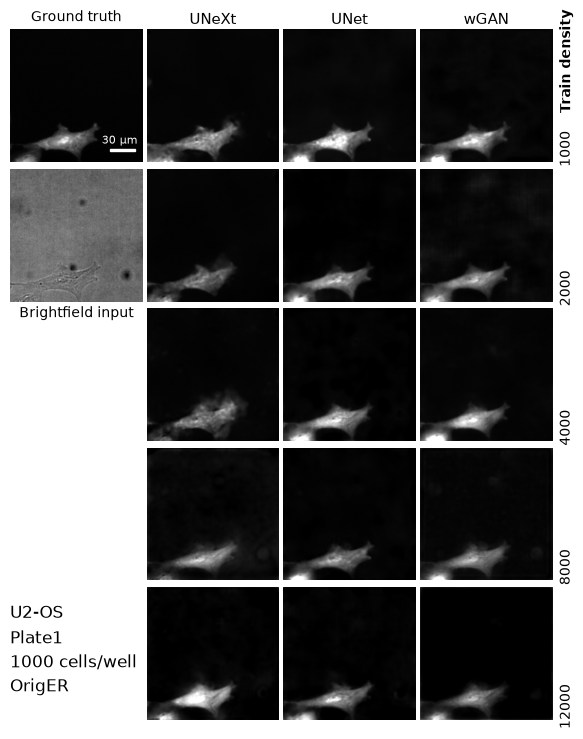

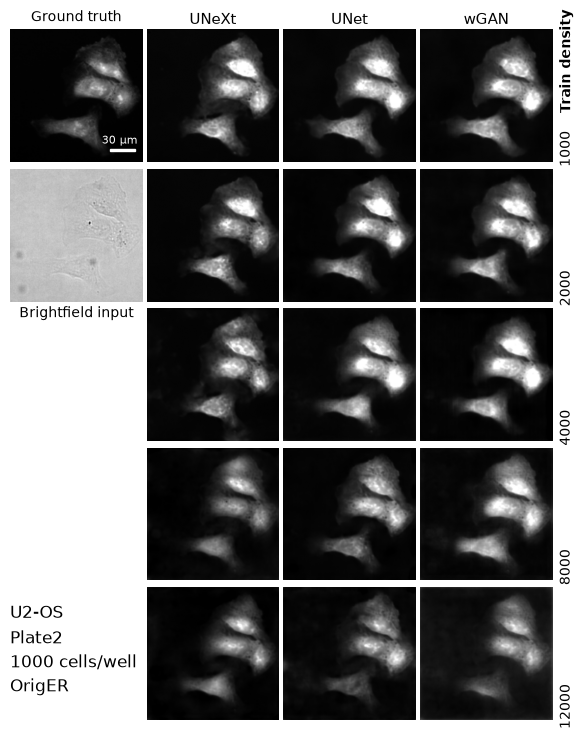

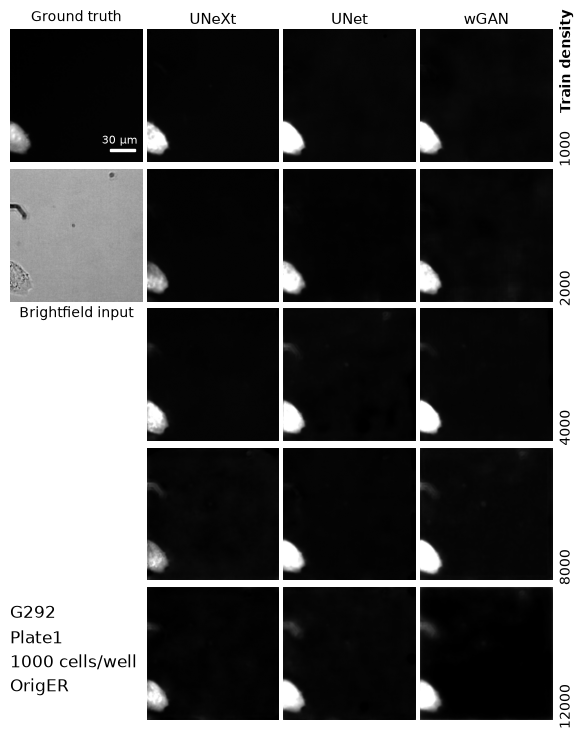

In [8]:
plot_out_dir.mkdir(parents=True, exist_ok=True)
if intensity_scaling not in {"reference", "dynamic"}:
    raise ValueError("intensity_scaling must be 'reference' or 'dynamic'.")

for sample in selected_samples:
    condition = sample["condition"]
    pair = sample["pair"]
    channel = sample["channel"]

    fig, axes = plt.subplots(
        len(train_densities),
        len(architectures) + 1,
        figsize=(7, 9),
        gridspec_kw={"wspace": 0.03, "hspace": 0.03},
    )
    for ax in axes.flat:
        ax.axis("off")

    # Convert the CPU tensor before NumPy masking and share fluorescence limits.
    reference = pair.reference_image.numpy()
    reference_finite = reference[np.isfinite(reference)]
    if intensity_scaling == "reference":
        vmin = float(reference_finite.min())
        vmax = float(reference_finite.max())
        if np.isclose(vmin, vmax):
            tolerance = max(abs(vmin) * 1e-6, 1e-6)
            vmin -= tolerance
            vmax += tolerance
        image_kwargs = {"vmin": vmin, "vmax": vmax}
    else:
        image_kwargs = {}

    axes[0, 0].imshow(reference, cmap="gray", **image_kwargs)
    axes[0, 0].set_title("Ground truth", fontsize=10)
    add_scale_bar(axes[0, 0], pixel_res=pixel_res_um, scalebar_loc=(0.75, 0.9))

    # Bright-field has its own intensity range, independent of fluorescence.
    axes[1, 0].imshow(sample["input_pair"].reference_image, cmap="gray")
    axes[2, 0].text(
        0.5, 0.9, "Brightfield input",
        transform=axes[2, 0].transAxes,
        ha="center", va="bottom", fontsize=10,
    )

    platemap_name = (
        condition.platemap_file
        .removeprefix("Assay_")
        .removesuffix("_platemap")
    )
    condition_text = (
        f"{condition.cell_line}\n"
        f"{platemap_name}\n"
        f"{condition.seeding_density} cells/well\n"
        f"{channel}"
    )
    axes[4, 0].text(
        0.0, 0.9, condition_text,
        transform=axes[4, 0].transAxes,
        ha="left", va="top", fontsize=12, linespacing=1.5,
    )

    if pair.degraded_stack.shape[0] > len(train_densities) * len(architectures):
        raise ValueError(
            f"Prediction stack has {pair.degraded_stack.shape[0]} images, but the "
            "montage only has space for "
            f"{len(train_densities) * len(architectures)}."
        )

    # Saved pages are architecture-major, then training-density-minor.
    # Keep these labels consistent with model_catalogue when regenerating predictions.
    for page_index, prediction in enumerate(pair.degraded_stack):
        row = page_index % len(train_densities)
        col = page_index // len(train_densities) + 1
        axes[row, col].imshow(prediction.numpy(), cmap="gray", **image_kwargs)

    for col, architecture in enumerate(architectures, start=1):
        axes[0, col].set_title(architecture, fontsize=11, pad=4)
    for row, density in enumerate(train_densities):
        axes[row, -1].text(
            1.05, 0.1, str(density),
            transform=axes[row, -1].transAxes,
            ha="left", va="center", fontsize=10, rotation=90,
        )
    axes[0, -1].text(
        1.05, 1.15, "Train density",
        transform=axes[0, -1].transAxes,
        ha="left", va="top", fontsize=10, fontweight="bold", rotation=90,
    )

    # Include biological context and scaling mode in each export filename.
    plot_path = plot_out_dir / (
        f"{condition.cell_line}_{platemap_name}_{condition.seeding_density}_"
        f"{condition.well or 'all_wells'}_{channel}_{intensity_scaling}.png"
    )
    fig.savefig(plot_path, dpi=600, bbox_inches="tight", facecolor="white")
    plt.show()